# Analyse en Composantes Principales (ACP) et classification

L'objectif de cette analyse est de réduire la dimension du jeu de données afin
d'identifier les principales caractéristiques permettant de différencier les pays,
puis de regrouper les pays présentant des profils similaires à l'aide d'une CAH
et d'un K-means.

In [1]:
# import du dataset final
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

base = Path.cwd()
if base.name == "Notebooks":
    base = base.parent
data_dir = base / "Données p11"
if not data_dir.is_dir():
    raise FileNotFoundError("Lancer le notebook depuis le dossier P11 ou Notebooks.")

df = pd.read_csv(data_dir / "df_final_cleaned.csv", sep=",", encoding="utf-8")

df.head()

,Zone_FR,Population,PIB_hab,Croissance_Pop,Urbanisation,Croissance_Urb,Stabilite_Politique,Qualite_Regulation,Production_volaille_hab,Importations_volaille_hab,Exportations_volaille_hab,Disponibilite_alimentaire_kg_hab,Poulet_Kcal_jour
0,afghanistan,36296113.0,525.47,2.81,24.84,3.52,-2.61,-1.42,0.77,0.80,0.00,1.53,5.0
1,afrique du sud,57009756.0,6618.34,0.65,63.33,0.74,-0.38,0.23,29.24,9.02,1.11,35.69,143.0
2,albanie,2884169.0,5006.36,-1.54,55.98,-0.81,0.16,0.11,4.51,13.18,0.00,16.36,85.0
3,algerie,41389189.0,4554.67,2.03,71.32,2.86,-0.93,-0.95,6.64,0.05,0.00,6.38,22.0
4,allemagne,82658409.0,45553.93,0.37,80.98,0.56,0.70,1.69,18.32,10.19,7.82,19.47,71.0


In [2]:
#Choix des variables ACP

variables_acp = [
    "PIB_hab",
    "Croissance_Pop",
    "Urbanisation",
    "Croissance_Urb",
    "Stabilite_Politique",
    "Qualite_Regulation",
    "Production_volaille_hab",
    "Importations_volaille_hab",
    "Exportations_volaille_hab",
    "Disponibilite_alimentaire_kg_hab"
]

df_acp = df[variables_acp].copy()

df_acp.head()

,PIB_hab,Croissance_Pop,Urbanisation,Croissance_Urb,Stabilite_Politique,Qualite_Regulation,Production_volaille_hab,Importations_volaille_hab,Exportations_volaille_hab,Disponibilite_alimentaire_kg_hab
0,525.47,2.81,24.84,3.52,-2.61,-1.42,0.77,0.80,0.00,1.53
1,6618.34,0.65,63.33,0.74,-0.38,0.23,29.24,9.02,1.11,35.69
2,5006.36,-1.54,55.98,-0.81,0.16,0.11,4.51,13.18,0.00,16.36
3,4554.67,2.03,71.32,2.86,-0.93,-0.95,6.64,0.05,0.00,6.38
4,45553.93,0.37,80.98,0.56,0.70,1.69,18.32,10.19,7.82,19.47


In [3]:
# Vérification de la propreté du dataset
df_acp.info()
df_acp.isna().sum()
df_acp.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 164 entries, 0 to 163
Data columns (total 10 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   PIB_hab                           164 non-null    float64
 1   Croissance_Pop                    164 non-null    float64
 2   Urbanisation                      164 non-null    float64
 3   Croissance_Urb                    164 non-null    float64
 4   Stabilite_Politique               164 non-null    float64
 5   Qualite_Regulation                164 non-null    float64
 6   Production_volaille_hab           164 non-null    float64
 7   Importations_volaille_hab         164 non-null    float64
 8   Exportations_volaille_hab         164 non-null    float64
 9   Disponibilite_alimentaire_kg_hab  164 non-null    float64
dtypes: float64(10)
memory usage: 12.9 KB


,PIB_hab,Croissance_Pop,Urbanisation,Croissance_Urb,Stabilite_Politique,Qualite_Regulation,Production_volaille_hab,Importations_volaille_hab,Exportations_volaille_hab,Disponibilite_alimentaire_kg_hab
count,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000
mean,13870.041646,1.195000,59.038171,1.856829,-0.086829,0.048476,16.401707,10.797805,3.598354,20.267073
std,18844.177159,1.289686,21.783010,1.843423,0.868203,0.894118,17.463476,18.595298,11.404800,15.796669
min,432.320000,-2.610000,15.960000,-2.370000,-2.730000,-1.830000,0.000000,0.000000,0.000000,0.130000
25%,1996.742500,0.225000,40.760000,0.482500,-0.655000,-0.660000,2.227500,0.570000,0.000000,6.910000
50%,6025.225000,1.240000,60.545000,1.775000,-0.020000,-0.065000,9.615000,3.685000,0.000000,18.235000
75%,17115.822500,2.235000,76.277500,2.977500,0.662500,0.565000,26.082500,11.720000,1.695000,29.485000
max,110193.210000,3.690000,100.000000,8.900000,1.490000,2.190000,76.300000,124.140000,90.740000,72.310000


In [4]:
# variables aux distribution très asymétriques

variables_log = [
    "PIB_hab",
    "Production_volaille_hab",
    "Importations_volaille_hab",
    "Exportations_volaille_hab"
]

for col in variables_log:
    df_acp[col] = np.log1p(df_acp[col])


Une transformation logarithmique a été appliquée aux variables très asymétriques afin de réduire l’influence des valeurs extrêmes et d’améliorer la stabilité de l’ACP.

In [5]:
# standardisation des données

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_acp)


Les variables ont été standardisées afin de les ramener sur une échelle commune et d’éviter qu’une variable à grande amplitude domine l’ACP.

In [6]:
# ACP

from sklearn.decomposition import PCA

pca = PCA()
X_pca = pca.fit_transform(X_scaled)


L’ACP permet de résumer l’information contenue dans l’ensemble des variables en quelques composantes principales, facilitant la visualisation et la segmentation des pays.

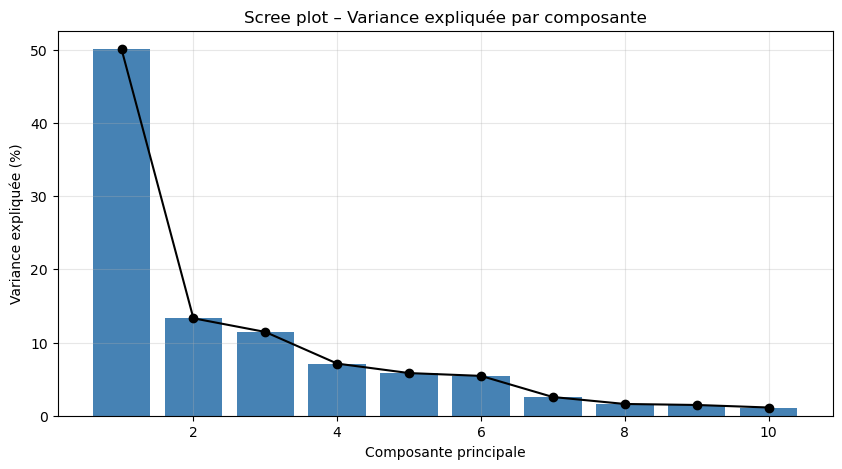

In [7]:
#variance

variance = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(10,5))
plt.bar(range(1, len(variance)+1), variance, color="steelblue")
plt.plot(range(1, len(variance)+1), variance, marker="o", color="black")
plt.xlabel("Composante principale")
plt.ylabel("Variance expliquée (%)")
plt.title("Scree plot – Variance expliquée par composante")
plt.grid(alpha=0.3)
plt.show()



La première composante explique environ 50 % de la variance totale, les deux suivantes environ 13 % et 12 %. 
Les trois premières composantes capturent donc près de 75 % de l’information, ce qui justifie leur utilisation pour l’analyse.

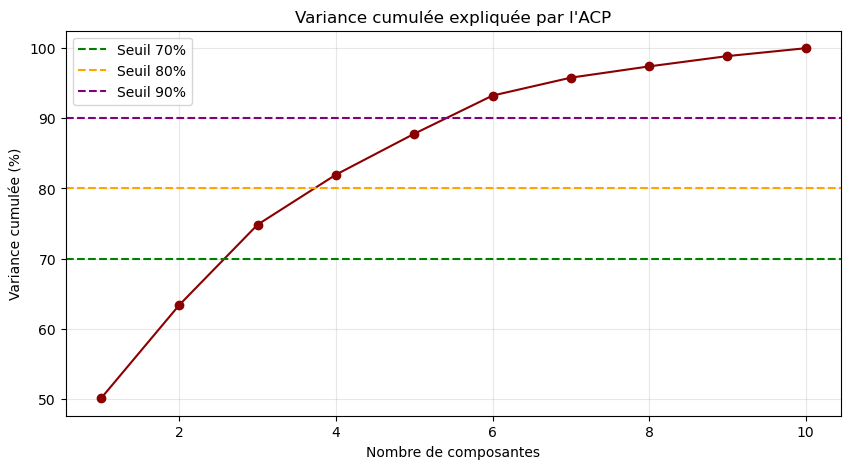

In [8]:
# variance cumulée

variance_cumulee = np.cumsum(variance)

plt.figure(figsize=(10,5))
plt.plot(range(1, len(variance_cumulee)+1), variance_cumulee, marker="o", color="darkred")
plt.axhline(70, color="green", linestyle="--", label="Seuil 70%")
plt.axhline(80, color="orange", linestyle="--", label="Seuil 80%")
plt.axhline(90, color="purple", linestyle="--", label="Seuil 90%")
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance cumulée (%)")
plt.title("Variance cumulée expliquée par l'ACP")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


La courbe de variance cumulée indique que le seuil de 70 % est atteint dès la troisième composante. 
Les composantes suivantes apportent peu d’information supplémentaire, ce qui confirme que trois composantes constituent un choix optimal pour l’ACP.

In [9]:
# Analyse des 3 PC sélectionnés pour l'ACP

loadings = pd.DataFrame(
    pca.components_[:3].T,
    columns=["PC1", "PC2", "PC3"],
    index=df_acp.columns
).round(2)

loadings



,PC1,PC2,PC3
PIB_hab,0.41,0.08,0.18
Croissance_Pop,-0.29,0.27,0.57
Urbanisation,0.32,-0.11,0.26
Croissance_Urb,-0.32,0.27,0.51
Stabilite_Politique,0.32,0.39,0.04
Qualite_Regulation,0.37,0.14,0.29
Production_volaille_hab,0.28,-0.52,0.23
Importations_volaille_hab,0.23,0.60,-0.28
Exportations_volaille_hab,0.29,-0.12,0.29
Disponibilite_alimentaire_kg_hab,0.31,0.12,-0.10


Composition des 3 PC:

L’ACP met en évidence trois axes majeurs qui résument 75 % de l’information du dataset :

PC1 – Développement socio‑économique  
Cette composante regroupe les variables liées au niveau de richesse, à l’urbanisation, à la stabilité politique et à la qualité des institutions. Elle oppose les pays développés et stables aux pays plus pauvres et ruraux.

PC2 – Structure industrielle avicole  
Cet axe distingue les pays producteurs/exportateurs de volaille des pays dépendants des importations. Il reflète le degré d’autosuffisance ou de dépendance du secteur avicole.

PC3 – Dynamique démographique  
Cette composante est portée par la croissance de la population et de l’urbanisation. Elle oppose les pays en forte expansion démographique aux pays à démographie stable ou en déclin.

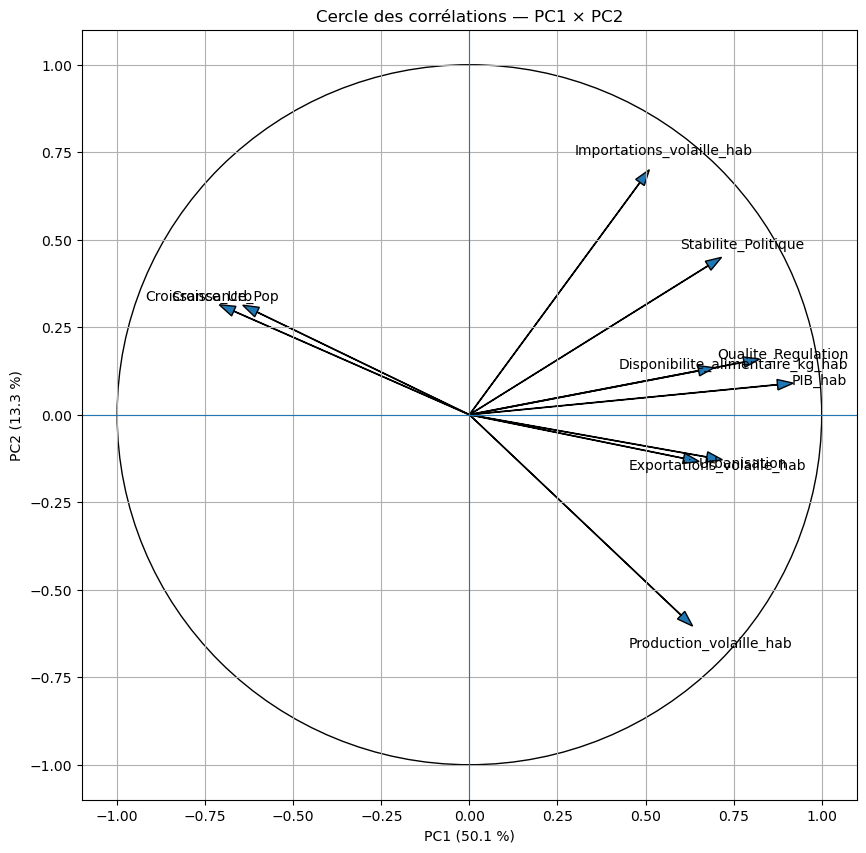

In [10]:
# cercle de corrélation PC1 x PC2

# Coordonnées des variables sur les axes 1 et 2
coord_var = pca.components_.T[:, :2] * np.sqrt(pca.explained_variance_[:2])

plt.figure(figsize=(10, 10))

# Cercle
cercle = plt.Circle((0, 0), 1, fill=False)
plt.gca().add_artist(cercle)

# Flèches et noms des variables
for i, variable in enumerate(df_acp.columns):
    plt.arrow(
        0, 0,
        coord_var[i, 0],
        coord_var[i, 1],
        head_width=0.03,
        length_includes_head=True
    )
    
    plt.text(
        coord_var[i, 0] * 1.08,
        coord_var[i, 1] * 1.08,
        variable,
        ha="center",
        va="center"
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlim(-1.1, 1.1)
plt.ylim(-1.1, 1.1)

plt.xlabel(f"PC1 ({variance[0]:.1f} %)")
plt.ylabel(f"PC2 ({variance[1]:.1f} %)")
plt.title("Cercle des corrélations — PC1 × PC2")

plt.grid()
plt.show()


Le cercle des corrélations montre que PC1 regroupe les variables liées au développement socio‑économique, tandis que PC2 oppose les pays producteurs aux pays importateurs de volaille. 

Lecture du graphe : 
Le cercle des corrélations est une représentation qualitative donc les graduations servent uniquement de repères visuels et ne doivent pas être interprétées comme des valeurs numériques

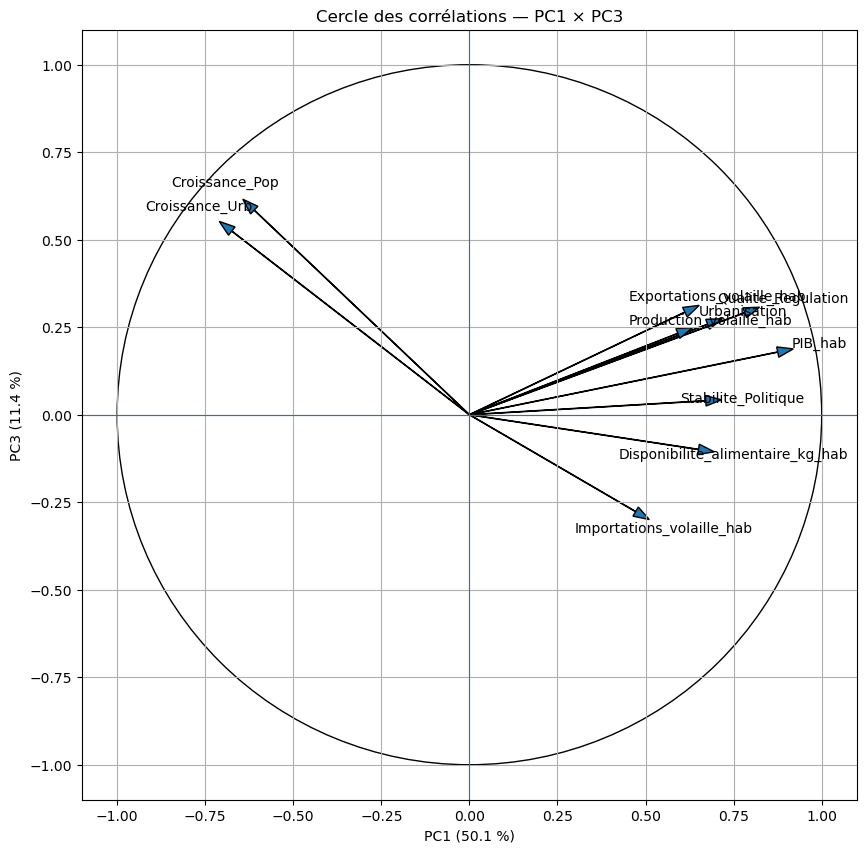

In [11]:
# cercle de corrélations PC1 x PC3

# Coordonnées des variables sur les axes 1 et 3
coord_var_13 = pca.components_.T[:, [0, 2]] * np.sqrt(pca.explained_variance_[[0, 2]])

plt.figure(figsize=(10, 10))

# Cercle
cercle = plt.Circle((0, 0), 1, fill=False)
plt.gca().add_artist(cercle)

# Flèches + noms des variables
for i, variable in enumerate(df_acp.columns):
    plt.arrow(
        0, 0,
        coord_var_13[i, 0],
        coord_var_13[i, 1],
        head_width=0.03,
        length_includes_head=True
    )
    
    plt.text(
        coord_var_13[i, 0] * 1.08,
        coord_var_13[i, 1] * 1.08,
        variable,
        ha="center",
        va="center"
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlim(-1.1, 1.1)
plt.ylim(-1.1, 1.1)

plt.xlabel(f"PC1 ({variance[0]:.1f} %)")
plt.ylabel(f"PC3 ({variance[2]:.1f} %)")
plt.title("Cercle des corrélations — PC1 × PC3")

plt.grid()
plt.show()


Le plan PC1 × PC3 oppose le niveau de développement des pays (PC1) à leur dynamique démographique (PC3).

Lecture du graphe : 
Le cercle des corrélations est une représentation qualitative donc les graduations servent uniquement de repères visuels et ne doivent pas être interprétées comme des valeurs numériques

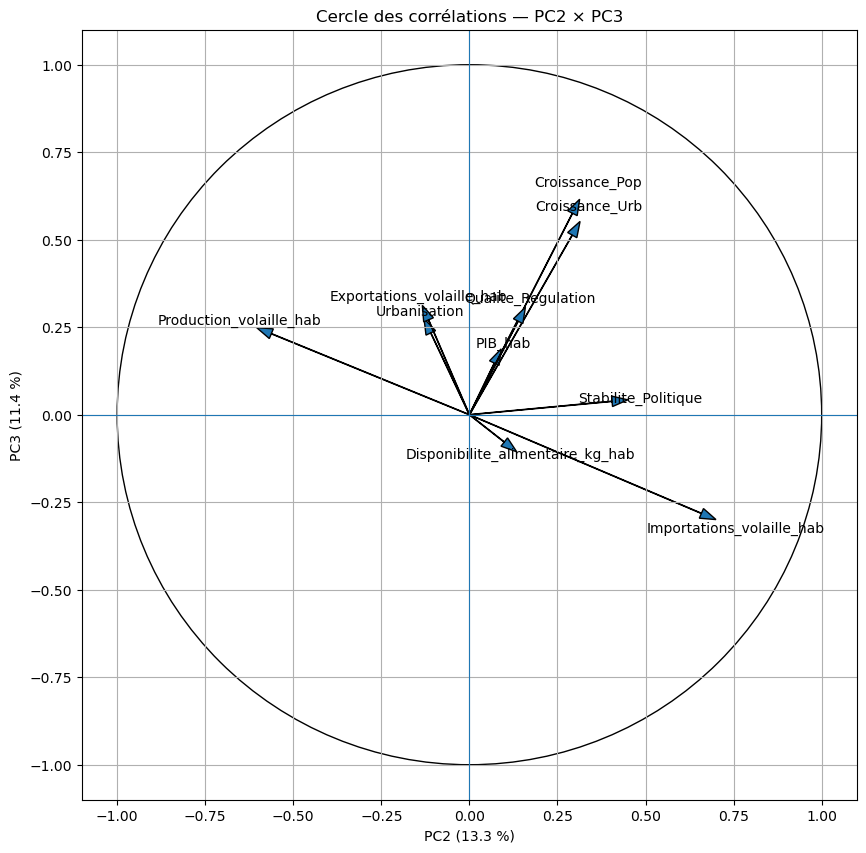

In [12]:
# Coordonnées des variables sur les axes 2 et 3
coord_var_23 = pca.components_.T[:, [1, 2]] * np.sqrt(pca.explained_variance_[[1, 2]])

plt.figure(figsize=(10, 10))

# Cercle
cercle = plt.Circle((0, 0), 1, fill=False)
plt.gca().add_artist(cercle)

# Flèches + noms des variables
for i, variable in enumerate(df_acp.columns):
    plt.arrow(
        0, 0,
        coord_var_23[i, 0],
        coord_var_23[i, 1],
        head_width=0.03,
        length_includes_head=True
    )
    
    plt.text(
        coord_var_23[i, 0] * 1.08,
        coord_var_23[i, 1] * 1.08,
        variable,
        ha="center",
        va="center"
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlim(-1.1, 1.1)
plt.ylim(-1.1, 1.1)

plt.xlabel(f"PC2 ({variance[1]:.1f} %)")
plt.ylabel(f"PC3 ({variance[2]:.1f} %)")
plt.title("Cercle des corrélations — PC2 × PC3")

plt.grid()
plt.show()



Le plan PC2 × PC3 est présenté sans le cercle de corrélation afin de simplifier la lecture. 
Ce plan met en évidence l’opposition entre importations et production avicole (PC2), ainsi que la dynamique démographique portée par PC3.

In [13]:
# creation d'un dataframe pour les graphes suivants
import plotly.express as px

df_pca = pd.DataFrame(
    X_pca[:, :3],
    columns=["PC1", "PC2", "PC3"]
)

df_pca["Pays"] = df["Zone_FR"]

# Arrondir les valeurs PCA à 2 décimales
df_pca["PC1"] = df_pca["PC1"].round(2)
df_pca["PC2"] = df_pca["PC2"].round(2)
df_pca["PC3"] = df_pca["PC3"].round(2)

fig = px.scatter(
    df_pca,
    x="PC1",
    y="PC2",
    hover_name="Pays",
    title="Projection des pays sur le plan factoriel"
)

fig.update_layout(width=1100, height=700)

fig.show()




Les valeurs PC1 et PC2 représentent les coordonnées des pays dans l’espace des composantes principales. 
Une valeur élevée (positive ou négative) indique que le pays est fortement marqué par l’axe correspondant, tandis qu’une valeur proche de zéro traduit un profil plus neutre. 
PC1 reflète principalement le niveau de développement socio‑économique, et PC2 distingue les pays selon leur profil avicole (production vs importation). 

In [14]:
# Projection des pays PC1 x PC3

import plotly.express as px
import pandas as pd

# Coordonnées PCA
X_pca = pca.transform(df_acp)

df_pca = pd.DataFrame(
    X_pca[:, :3],
    columns=["PC1", "PC2", "PC3"]
)

# Ajouter les noms des pays
df_pca["Pays"] = df["Zone_FR"]

# Arrondir les valeurs à 2 décimales
df_pca["PC1"] = df_pca["PC1"].round(2)
df_pca["PC3"] = df_pca["PC3"].round(2)

# Graphique Plotly PC1 × PC3
fig = px.scatter(
    df_pca,
    x="PC1",
    y="PC3",
    hover_name="Pays",
    title="Projection des pays — PC1 × PC3 (Plotly)"
)

# Agrandir la figure
fig.update_layout(
    width=1100,
    height=700
)

fig.show()


Les valeurs PC1 et PC3 représentent les coordonnées des pays dans l’espace des composantes principales. 
Une valeur élevée (positive ou négative) indique que le pays est fortement marqué par l’axe correspondant, tandis qu’une valeur proche de zéro traduit un profil plus neutre. 
PC1 reflète principalement le niveau de développement socio‑économique, et PC3 distingue les pays selon leur profil démographique (croissance poupulation et urbanisation). 

Après l’ACP, l’objectif est de regrouper les pays selon leurs similarités.
La CAH permet de construire une classification hiérarchique à partir des coordonnées des pays sur les composantes principales.

Nous utilisons les 3 premiers axes de l’ACP, car ils concentrent l’essentiel de l’information structurante.

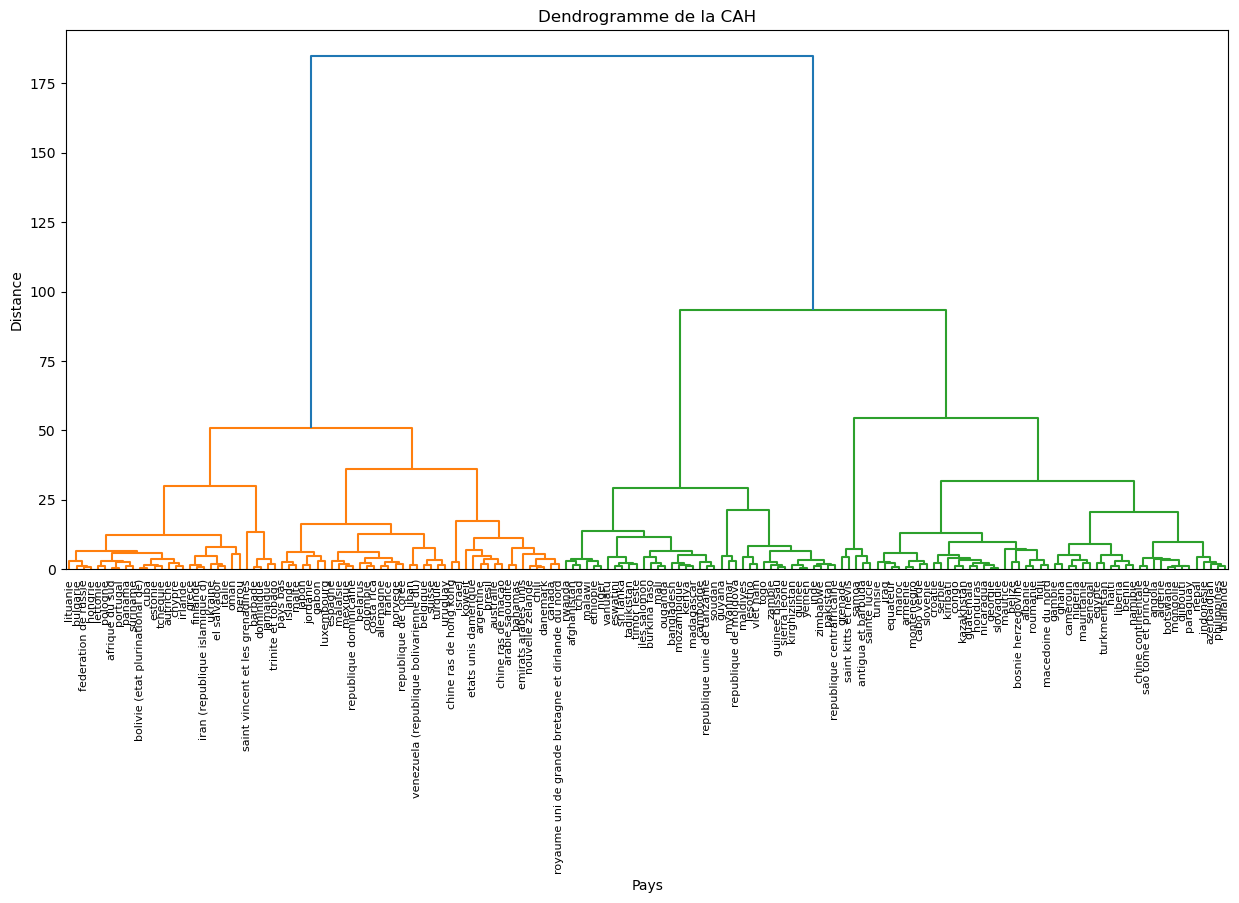

In [ ]:
# Coordonnées des pays sur les 3 premières composantes
X_clustering = X_pca[:, :3]

from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

Z = linkage(X_clustering, method="ward")

plt.figure(figsize=(15, 7))

dendrogram(
    Z,
    labels=df["Zone_FR"].values, 
    leaf_rotation=90,
    leaf_font_size=8
)

plt.title("Dendrogramme de la CAH")
plt.xlabel("Pays")
plt.ylabel("Distance")
plt.show()


Le dendrogramme obtenu permet de visualiser la manière dont les pays se regroupent en fonction de leurs similarités sur les trois premières composantes de l’ACP.

In [16]:
# choix du nombre de clusters

from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

scores = {}

for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_clustering)
    scores[k] = silhouette_score(X_clustering, labels)

scores


{2: np.float64(0.49484033332855454),
 3: np.float64(0.4663820236488405),
 4: np.float64(0.48683193258488394),
 5: np.float64(0.45711719178214455),
 6: np.float64(0.41109709149770446),
 7: np.float64(0.3846270513628345),
 8: np.float64(0.3927810494327371)}

Choix du nombre de clusters :
Le score de silhouette est maximal pour k = 2, mais ce nombre de clusters est trop peu informatif pour une segmentation pays. 
Les valeurs obtenues pour k = 3 et k = 4 restent élevées et correspondent aux ruptures visibles dans le dendrogramme. 
Nous retenons donc k = 4, qui offre un compromis optimal entre qualité de partitionnement et interprétabilité métier.

In [17]:
#lancement du k-means
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_clustering)

df["Cluster"] = clusters


In [18]:
# Obtenir le nombre de pays pour chaque cluster

df["Cluster"].value_counts().sort_index()

Cluster
0    48
1    67
2    39
3    10
Name: count, dtype: int64

In [19]:
# Identification des profils des 4 clusters

profil_clusters = df.groupby("Cluster")[variables_acp].mean().round(2)

profil_clusters

,PIB_hab,Croissance_Pop,Urbanisation,Croissance_Urb,Stabilite_Politique,Qualite_Regulation,Production_volaille_hab,Importations_volaille_hab,Exportations_volaille_hab,Disponibilite_alimentaire_kg_hab
Cluster,,,,,,,,,,
0,4951.83,1.11,57.76,1.93,-0.26,-0.26,10.15,6.09,1.08,13.36
1,27714.67,0.74,79.52,0.93,0.32,0.68,28.15,13.69,8.03,29.26
2,1717.13,2.32,31.45,3.65,-0.76,-0.71,3.49,2.44,0.00,4.89
3,11314.78,0.26,35.56,0.69,0.61,0.20,18.04,46.64,0.03,53.12


In [20]:
# Pays composants les différents cluster
for cluster in sorted(df["Cluster"].unique()):
    print(f"\nCluster {cluster} ")
    print(df.loc[df["Cluster"] == cluster, "Zone_FR"].tolist())


Cluster 0 
['albanie', 'algerie', 'angola', 'armenie', 'azerbaidjan', 'belize', 'benin', 'bosnie herzegovine', 'botswana', 'cabo verde', 'cameroun', 'chine continentale', 'congo', 'croatie', 'djibouti', 'egypte', 'equateur', 'fidji', 'gambie', 'georgie', 'ghana', 'guatemala', 'haiti', 'honduras', 'indonesie', 'iraq', 'kazakhstan', 'kiribati', 'liberia', 'macedoine du nord', 'maroc', 'mauritanie', 'mongolie', 'montenegro', 'namibie', 'nepal', 'nicaragua', 'nigeria', 'paraguay', 'philippines', 'republique de moldova', 'roumanie', 'sao tome et principe', 'serbie', 'slovaquie', 'slovenie', 'thailande', 'tunisie']

Cluster 1 
['afrique du sud', 'allemagne', 'arabie saoudite', 'argentine', 'australie', 'autriche', 'bahamas', 'barbade', 'belarus', 'belgique', 'bolivie (etat plurinational de)', 'bresil', 'bulgarie', 'canada', 'chili', 'chine ras de hong kong', 'chine ras de macao', 'chypre', 'colombie', 'costa rica', 'cuba', 'danemark', 'dominique', 'el salvador', 'emirats arabes unis', 'espa

Détails clusters:

Cluster 0 (48 pays) :
Ce cluster regroupe principalement des pays présentant un niveau de développement économique intermédiaire, avec une urbanisation relativement importante et une filière avicole déjà présente.
La production et les importations de volaille restent modérées, ce qui peut traduire des marchés en développement offrant des opportunités de croissance, mais avec des niveaux de pouvoir d'achat et de stabilité institutionnelle variables.

Positionnement : marché en croissance, avec des opportunités à moyen terme mais des risques variables.
Exemples : Algérie, Maroc, Ghana, Indonésie, Philippines, Kazakhstan, Serbie.


Cluster 1 (67 pays) : 
Ce cluster regroupe des pays présentant un PIB par habitant moyen à élevé, une urbanisation importante et une filière avicole développée. 
La production locale y est solide et s’accompagne d’importations et d’exportations actives, ce qui traduit des marchés dynamiques et structurés. L’environnement institutionnel est globalement stable, favorisant une filière organisée et une demande soutenue.

Il rassemble des pays développés comme l’Allemagne, les États-Unis, la France ou le Japon, mais aussi des pays émergents tels que la Colombie, le Costa Rica ou le Panama, dont le profil avicole et alimentaire est statistiquement proche de celui des marchés matures.

Positionnement : marchés solvables, matures ou semi‑matures, avec une forte activité commerciale et une concurrence importante.


Cluster 2 (39 Pays) :
Ce cluster regroupe des pays présentant un faible PIB par habitant, une urbanisation encore limitée et une filière avicole peu développée.
En revanche, ils se caractérisent par une forte croissance démographique et urbaine, ce qui peut constituer un facteur de développement futur de la demande alimentaire.

Positionnement : potentiel à long terme, mais pouvoir d'achat actuellement limité et environnement institutionnel plus fragile.
Exemples : Afghanistan, Bangladesh, Inde, Kenya, Tanzanie, Rwanda, Sénégal.


Cluster 3 (10 Pays) :
Ce cluster constitue le profil le plus spécifique. Il regroupe principalement de petits États insulaires et pays des Caraïbes, caractérisés par une production locale relativement limitée et surtout par un niveau d'importations de volaille très élevé par habitant.
Avec environ 46,6 kg d'importations par habitant, contre seulement 0,03 kg d'exportations, ces marchés présentent une forte dépendance aux approvisionnements extérieurs.

Positionnement : marchés particulièrement intéressants pour les exportateurs, sous réserve de prendre en compte leur taille de marché relativement limitée.
Exemples : Jamaïque, Maurice, Trinité-et-Tobago, Sainte-Lucie, Grenade, Samoa.


In [26]:
# Création des indicateurs réels


df["Importations_totales_kg"] = df["Importations_volaille_hab"] * df["Population"]
df["Production_totale_kg"] = df["Production_volaille_hab"] * df["Population"]

df["Dependance_importations"] = (
    df["Importations_totales_kg"] /
    (df["Importations_totales_kg"] + df["Production_totale_kg"])
).replace([np.inf, -np.inf], np.nan)

# Synthèse par cluster

synthese = df.groupby("Cluster").agg(
    Population_totale=("Population", "sum"),
    Importations_totales=("Importations_totales_kg", "sum"),
    Production_totale=("Production_totale_kg", "sum"),
    PIB_moyen=("PIB_hab", "mean"),
    Disponibilite_moyenne=("Disponibilite_alimentaire_kg_hab", "mean"),
    Stabilite_politique_moyenne=("Stabilite_Politique", "mean"),
    Qualite_regulation_moyenne=("Qualite_Regulation", "mean")
)

# Dépendance au niveau du cluster
synthese["Dependance"] = (
    synthese["Importations_totales"] /
    (synthese["Importations_totales"] + synthese["Production_totale"])
)

# Formatage pour la lisibilité


indicateurs_formatted = synthese.map(
    lambda x: f"{x:,.2f}".replace(",", " ") if isinstance(x, (int, float)) else x
)

indicateurs_formatted


,Population_totale,Importations_totales,Production_totale,PIB_moyen,Disponibilite_moyenne,Stabilite_politique_moyenne,Qualite_regulation_moyenne,Dependance
Cluster,,,,,,,,
0,2 578 165 274.00,2 998 210 960.09,28 581 927 282.71,4 951.83,13.36,-0.26,-0.26,0.09
1,2 146 744 427.00,11 173 949 667.50,82 951 349 093.51,27 714.67,29.26,0.32,0.68,0.12
2,2 513 870 187.00,662 913 868.03,9 114 028 418.36,1 717.13,4.89,-0.76,-0.71,0.07
3,7 089 106.00,109 990 643.69,269 989 308.41,11 314.78,53.12,0.61,0.20,0.29


Le cluster 1 constitue le marché le plus important en volume d'importations et présente un pouvoir d'achat élevé, mais il est également caractérisé par une forte production locale. 
Le cluster 3 se distingue par la plus forte dépendance aux importations (29 %) et par un niveau élevé d'importations par habitant, ce qui en fait un profil particulièrement intéressant pour les exportateurs, malgré une population limitée. 
Le cluster 0 présente un marché de grande taille mais relativement autonome grâce à sa production locale, tandis que le cluster 2 apparaît davantage comme un marché de long terme compte tenu de son faible niveau de PIB et de ses faibles importations.

In [27]:
# Filtrer uniquement les clusters 1 et 3

df_filtre = df[df["Cluster"].isin([1, 3])].copy()


# Normalisation des critères

from sklearn.preprocessing import MinMaxScaler

criteres = [
    "Importations_totales_kg",
    "Dependance_importations",
    "PIB_hab",
    "Population",
    "Stabilite_Politique",
    "Qualite_Regulation"
]

scaler = MinMaxScaler()

for col in criteres:
    df_filtre[col + "_norm"] = scaler.fit_transform(
        df_filtre[[col]]
    )


# Score d'attractivité du marché
# 30% Importations
# 25% Dépendance aux importations
# 15% PIB/hab
# 10% Population
# 10% Stabilité politique
# 10% Qualité de la régulation

df_filtre["Score_attractivite"] = (
    df_filtre["Importations_totales_kg_norm"] * 0.30 +
    df_filtre["Dependance_importations_norm"] * 0.25 +
    df_filtre["PIB_hab_norm"] * 0.15 +
    df_filtre["Population_norm"] * 0.10 +
    df_filtre["Stabilite_Politique_norm"] * 0.10 +
    df_filtre["Qualite_Regulation_norm"] * 0.10
)


# Tri final

df_filtre = df_filtre.sort_values(
    by="Score_attractivite",
    ascending=False
).reset_index(drop=True)


# Colonnes utiles

colonnes_utiles = [
    "Cluster",
    "Zone_FR",
    "Population",
    "Importations_totales_kg",
    "Production_totale_kg",
    "PIB_hab",
    "Dependance_importations",
    "Stabilite_Politique",
    "Qualite_Regulation",
    "Score_attractivite"
]

df_resultats = df_filtre[colonnes_utiles].copy()


# Formatage

def format_milliers(x):
    if isinstance(x, (int, float)):
        return f"{x:,.0f}".replace(",", " ")
    return x


df_resultats_formatted = df_resultats.copy()


# Formatage des grandes valeurs

for col in [
    "Population",
    "Importations_totales_kg",
    "Production_totale_kg"
]:
    df_resultats_formatted[col] = (
        df_resultats_formatted[col].apply(format_milliers)
    )


# Formatage PIB

df_resultats_formatted["PIB_hab"] = (
    df_resultats_formatted["PIB_hab"]
    .apply(lambda x: f"{x:,.0f} USD".replace(",", " "))
)


# Formatage dépendance

df_resultats_formatted["Dependance_importations"] = (
    df_resultats_formatted["Dependance_importations"]
    .apply(lambda x: f"{x:.1%}")
)


# Formatage stabilité politique

df_resultats_formatted["Stabilite_Politique"] = (
    df_resultats_formatted["Stabilite_Politique"]
    .apply(lambda x: f"{x:.2f}")
)


# Formatage qualité de la régulation

df_resultats_formatted["Qualite_Regulation"] = (
    df_resultats_formatted["Qualite_Regulation"]
    .apply(lambda x: f"{x:.2f}")
)


# Formatage score

df_resultats_formatted["Score_attractivite"] = (
    df_resultats_formatted["Score_attractivite"]
    .apply(lambda x: f"{x:.3f}")
)


df_resultats_formatted

,Cluster,Zone_FR,Population,Importations_totales_kg,Production_totale_kg,PIB_hab,Dependance_importations,Stabilite_Politique,Qualite_Regulation,Score_attractivite
0,1,chine ras de hong kong,7 306 322,907 006 813,23 964 736,46 160 USD,97.4%,0.68,2.19,0.736
1,1,japon,127 502 725,1 068 472 836,2 214 722 333,39 680 USD,32.5%,1.17,1.40,0.643
2,1,luxembourg,591 910,10 997 688,0,110 193 USD,100.0%,1.27,1.64,0.583
3,1,allemagne,82 658 409,842 289 188,1 514 302 053,45 554 USD,35.7%,0.70,1.69,0.574
4,1,emirats arabes unis,9 487 203,432 995 945,48 005 247,43 734 USD,90.0%,0.72,1.11,0.556
...,...,...,...,...,...,...,...,...,...,...
72,3,guyana,775 222,0,31 001 128,6 179 USD,0.0%,-0.01,-0.37,0.095
73,1,turquie,81 116 450,3 244 658,2 191 766 479,10 756 USD,0.1%,-1.71,0.14,0.087
74,1,iran (republique islamique d),80 673 883,5 647 172,2 174 161 147,6 001 USD,0.3%,-0.70,-1.08,0.082
75,1,bolivie (etat plurinational de),11 192 855,1 007 357,533 003 755,4 048 USD,0.2%,-0.22,-0.83,0.078


## Marchés prioritaires
Ces pays combinent taille de marché, solvabilité, volumes d’importation élevés et risque limité.
Ils doivent constituer le cœur de la stratégie commerciale.

Pays prioritaires
Japon — grand marché, PIB élevé, importations importantes.

Allemagne — marché mature, solvable, volumes d’importation élevés.

Émirats arabes unis — très forte dépendance aux importations + pouvoir d’achat élevé.

Arabie saoudite — marché large, dépendance significative, croissance démographique.

Royaume‑Uni — gros volumes d’importation, PIB élevé, marché stable.

## Marchés à étudier spécifiquement
Ces pays présentent un score élevé, mais nécessitent une analyse complémentaire (contraintes, structure du marché, taille réelle, etc.).

Pays à analyser :
Hong Kong — score n°1, mais rôle de hub commercial à vérifier.

Mexique — population énorme et importations importantes, mais PIB/hab plus faible = sensibilité au prix.

Cuba — dépendance extrême, mais contraintes économiques et réglementaires.

Oman — forte dépendance, mais marché beaucoup plus petit.

Luxembourg — très riche et dépendant, mais marché minuscule = opportunité premium ciblée.

## Marchés non prioritaires malgré un score élevé
Certains pays obtiennent un score élevé uniquement grâce à leur dépendance, mais leur taille de marché est trop faible pour une stratégie structurée.

Exemple
Saint‑Kitts‑et‑Nevis — 100 % de dépendance, mais seulement ~52 000 habitants et ~4 M kg importés = marché trop petit pour être une priorité.

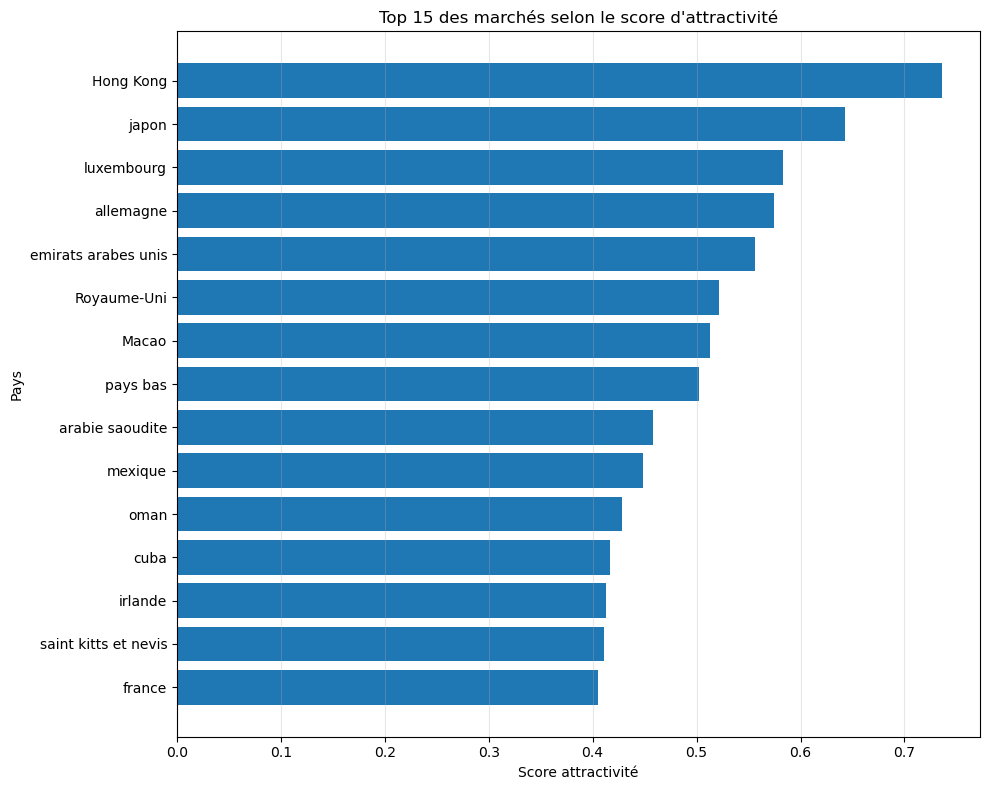

In [32]:
# Visualisation du top 15

import matplotlib.pyplot as plt

# Dictionnaire de noms abrégés
abreviations = {
    "royaume uni de grande bretagne et dirlande du nord": "Royaume-Uni",
    "chine ras de hong kong": "Hong Kong",
    "chine ras de macao": "Macao",
}

# Création de la colonne abrégée
df_filtre["Zone_FR_short"] = df_filtre["Zone_FR"].replace(abreviations)

# Visualisation du top 15

top15 = (
    df_filtre
    .sort_values("Score_attractivite", ascending=True)
    .tail(15)
)

plt.figure(figsize=(10, 8))

plt.barh(
    top15["Zone_FR_short"], 
    top15["Score_attractivite"]
)

plt.xlabel("Score attractivité")
plt.ylabel("Pays")
plt.title("Top 15 des marchés selon le score d'attractivité")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


### Analyse qualitative des marchés prioritaires

L'analyse du score commercial permet d'identifier plusieurs marchés présentant un potentiel intéressant pour une stratégie d'exportation de viande de volaille. Toutefois, le score ne suffit pas à lui seul pour sélectionner les marchés cibles. Une analyse qualitative complémentaire prenant en compte la taille du marché, le niveau économique, la dépendance aux importations et l'intensité de la concurrence permet d'affiner la sélection.

Le Japon apparaît comme l'un des marchés les plus intéressants. Avec une population importante, un PIB par habitant élevé et un volume d'importations conséquent, il offre un bon équilibre entre taille et capacité d'achat. Toutefois, le marché est mature et dispose également d'une production nationale importante, ce qui implique une concurrence élevée.

L'Allemagne présente un profil similaire. Son niveau de PIB par habitant est élevé et ses importations de volaille représentent un volume important. La taille du marché constitue un atout majeur, même si la production nationale importante implique également une forte concurrence.

Les Émirats arabes unis se distinguent par un profil particulièrement favorable à l'importation. Le pays combine un PIB par habitant élevé avec une forte dépendance aux importations de volaille. Les données disponibles indiquent également que la production nationale ne suffit pas à couvrir l'ensemble de la demande. Ce marché apparaît donc comme une cible prioritaire, sous réserve de prendre en compte la concurrence internationale et les exigences réglementaires.

L'Arabie saoudite constitue également un marché intéressant. Sa population est importante, ses importations sont élevées et sa dépendance aux importations est supérieure à celle de plusieurs autres marchés sélectionnés. La concurrence internationale y est cependant forte, notamment de la part du Brésil.

Le Royaume-Uni présente quant à lui un marché de grande taille avec un PIB par habitant élevé et un volume d'importations important. Sa dépendance aux importations est toutefois plus modérée, ce qui suggère un marché mature et concurrentiel plutôt qu'un marché fortement déficitaire en production.

Le Mexique constitue un cas particulier. Sa très grande population et son volume d'importations élevé représentent un potentiel commercial important. Cependant, la production nationale est également très importante et le marché est fortement concurrentiel. Il pourrait donc représenter une opportunité intéressante à moyen terme, mais nécessiterait une stratégie d'entrée plus compétitive.

Enfin, Hong Kong obtient le score commercial le plus élevé de l'analyse. Ses importations par habitant et sa dépendance aux importations sont particulièrement élevées. Ce résultat doit néanmoins être interprété avec prudence, car Hong Kong constitue également une importante plateforme commerciale et certains flux peuvent correspondre à des opérations de réexportation. Une analyse complémentaire des flux commerciaux serait donc nécessaire avant de le considérer comme une priorité.

À l'issue de cette analyse, les cinq marchés prioritaires retenus sont le Japon, l'Allemagne, les Émirats arabes unis, l'Arabie saoudite et le Royaume-Uni, tous issus du cluster n°1. Le Mexique est considéré comme un marché à fort potentiel mais plus concurrentiel, tandis que Hong Kong est conservé comme marché à investiguer davantage.
